# EDA: датасет поликлиники

Разбор `data/polyclinics/dataset.json` — оценочных пар «вопрос клиента / ответ».

Проверяю три вещи:

- объём: сколько пар, как они делятся на справочные и вопросы о записи, насколько длинные тексты;
- качество полей: пустые значения, схема, повтор вопроса с разными ответами;
- совпадает ли ответ о записи со слотом в таблице доступности.


In [1]:
import json
import re
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "font.size": 11,
    }
)

KIND_COLOR = {"knowledge": "#1f4e5f", "availability": "#c47b4a"}
KIND_LABEL = {"knowledge": "справочные", "availability": "запись"}


def project_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Не найден корень проекта.")


ROOT = project_root()
CLINIC = ROOT / "data" / "polyclinics"
rows = json.loads((CLINIC / "dataset.json").read_text(encoding="utf-8"))
calendar = json.loads((CLINIC / "availability.json").read_text(encoding="utf-8"))
info = json.loads((CLINIC / "info.json").read_text(encoding="utf-8"))
specialists = json.loads((CLINIC / "specialists.json").read_text(encoding="utf-8"))
cards = [{"name": item["name"]} for item in info]
cards.append({"name": "Специалисты"})
role_names = sorted({person["specialist"] for person in specialists}, key=len, reverse=True)

knowledge = [row for row in rows if row["kind"] == "knowledge"]
availability = [row for row in rows if row["kind"] == "availability"]
print(f"записей: {len(rows)}")
print(f"справочные: {len(knowledge)}")
print(f"запись: {len(availability)}")
print(f"карточек каталога: {len(cards)}")
print(f"специальностей: {len(role_names)}")
print(f"таблиц доступности: {len(calendar)}")

записей: 99
справочные: 15
запись: 84
карточек каталога: 5
специальностей: 21
таблиц доступности: 21


## Объём

Справочные карточки взяты с сайта поликлиники и только спарсены: название, контакты, режим работы, услуги и список специалистов. Других страниц с знаниями на сайте не было, поэтому справочник я не дописывал. Вопросы о записи собраны синтетически по тем 21 специальности, которые на сайте были: у каждой своя таблица слотов и четыре вопроса.

Клиент, которому нужно автоматизировать поддержку, может загрузить и другие документы — подготовку к анализам, стоимость услуг, памятки по филиалам. Тогда справочная часть для RAG станет больше, а запись останется привязанной к тем специальностям, которые он ведёт.


In [2]:
MONTHS = {
    name: index
    for index, name in enumerate(
        (
            "января",
            "февраля",
            "марта",
            "апреля",
            "мая",
            "июня",
            "июля",
            "августа",
            "сентября",
            "октября",
            "ноября",
            "декабря",
        ),
        start=1,
    )
}
WHEN_RE = re.compile(r"(\d{1,2}) (" + "|".join(MONTHS) + r") (\d{4}) года в (\d{2}:\d{2})")


def role_hits(question: str) -> list[str]:
    text = question.casefold()
    return [name for name in role_names if name.casefold() in text]


def parse_slot(question: str) -> tuple[str, datetime]:
    role = role_hits(question)[0]
    day, month, year, clock = WHEN_RE.search(question).groups()
    hour, minute = clock.split(":")
    moment = datetime(int(year), MONTHS[month], int(day), int(hour), int(minute))
    return role, moment


def lengths(items, field):
    return [len(item[field]) for item in items]

справочных карточек: 5, специальностей для записи: 21 (4.2×)
справочных вопросов: 15 (по 3 на карточку), вопросов о записи: 84 (по 4 на специальность, 5.6×)


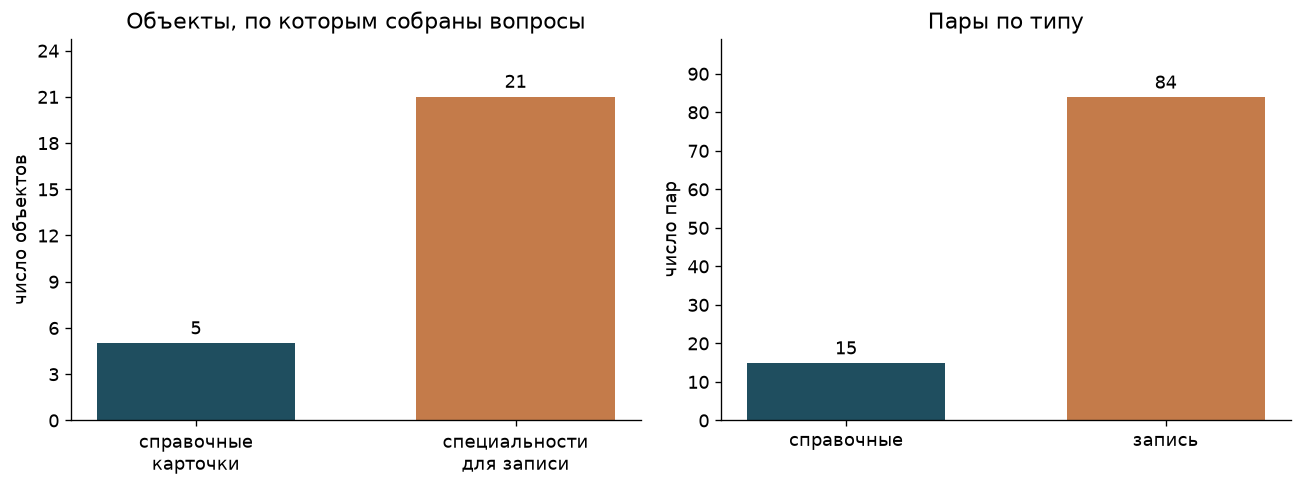

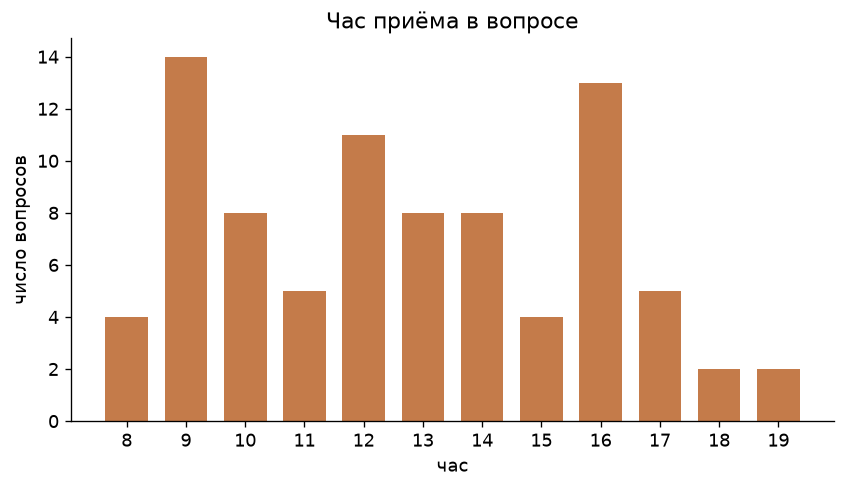

In [3]:
print(
    f"справочных карточек: {len(cards)}, "
    f"специальностей для записи: {len(role_names)} "
    f"({len(role_names) / len(cards):.1f}×)"
)
print(
    f"справочных вопросов: {len(knowledge)} "
    f"(по {len(knowledge) // len(cards)} на карточку), "
    f"вопросов о записи: {len(availability)} "
    f"(по {len(availability) // len(role_names)} на специальность, "
    f"{len(availability) / len(knowledge):.1f}×)"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

card_labels = ["справочные\nкарточки", "специальности\nдля записи"]
card_values = [len(cards), len(role_names)]
bars = axes[0].bar(card_labels, card_values, color=list(KIND_COLOR.values()), width=0.62)
axes[0].set_title("Объекты, по которым собраны вопросы")
axes[0].set_ylabel("число объектов")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, card_values, strict=True):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, value + 0.3, str(value), ha="center", va="bottom"
    )
axes[0].set_ylim(0, max(card_values) * 1.18)

kind_counts = Counter(row["kind"] for row in rows)
labels = [KIND_LABEL[kind] for kind in ("knowledge", "availability")]
values = [kind_counts[kind] for kind in ("knowledge", "availability")]
bars = axes[1].bar(labels, values, color=list(KIND_COLOR.values()), width=0.62)
axes[1].set_title("Пары по типу")
axes[1].set_ylabel("число пар")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, values, strict=True):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 1, str(value), ha="center", va="bottom")
axes[1].set_ylim(0, max(values) * 1.18)

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2))
hours = Counter(parse_slot(row["question"])[1].hour for row in availability)
hour_order = list(range(min(hours), max(hours) + 1))
ax.bar(
    [str(hour) for hour in hour_order],
    [hours[hour] for hour in hour_order],
    color=KIND_COLOR["availability"],
    width=0.72,
)
ax.set_title("Час приёма в вопросе")
ax.set_xlabel("час")
ax.set_ylabel("число вопросов")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

## Качество

Ответ о записи сверяю с `availability.json`: «Да», только если свободен этот слот специальности.
Имя специальности беру самое длинное из тех, что входят в вопрос: «Врач-терапевт» входит в «Врач-терапевт участковый», «Медсестра (медбрат)» — в должности с тем же началом.


In [4]:
required = {"kind", "question", "answer"}
unknown_keys = [sorted(row) for row in rows if set(row) != required]
empty = [
    index
    for index, row in enumerate(rows)
    if not str(row.get("question", "")).strip() or not str(row.get("answer", "")).strip()
]
unknown_kinds = sorted({row["kind"] for row in rows} - set(KIND_LABEL))
bad_answers = [row["answer"] for row in availability if row["answer"] not in {"Да", "Нет"}]

by_question = defaultdict(list)
for row in rows:
    by_question[row["question"]].append(row)
conflicts = {
    question: items
    for question, items in by_question.items()
    if len({item["answer"] for item in items}) > 1
}

slots_by_role = {
    item["subject"]: {
        datetime.fromisoformat(slot["date"]): slot["available"] for slot in item["slots"]
    }
    for item in calendar
}
calendar_mismatch = []
calendar_unparsed = []
per_role = Counter()
overlapping_roles = Counter()
for row in availability:
    hits = role_hits(row["question"])
    if len(hits) > 1:
        overlapping_roles[tuple(reversed(hits))] += 1
    try:
        role, moment = parse_slot(row["question"])
        expected = "Да" if slots_by_role[role][moment] else "Нет"
    except (KeyError, IndexError, AttributeError):
        calendar_unparsed.append(row["question"])
        continue
    per_role[role] += 1
    if expected != row["answer"]:
        calendar_mismatch.append((row["question"], row["answer"], expected))

print(f"""схема не {{kind, question, answer}}: {len(unknown_keys)}
пустые вопрос или ответ: {len(empty)}
неизвестные kind: {unknown_kinds or "нет"}
""")

print(f"повтор вопроса с разными ответами: {len(conflicts)}")
for question, items in conflicts.items():
    print(f"  {question}")
    for item in items:
        print(f"    [{item['kind']}] {item['answer']}")

print(f"""
ответы о записи вне «Да»/«Нет»: {len(bad_answers)}
ответы о записи расходятся со слотом: {len(calendar_mismatch)}
вопросы о записи не разобраны: {len(calendar_unparsed)}
вопросов на специальность: {min(per_role.values())}–{max(per_role.values())}
""")

print("вопросы, где короткое имя специальности входит в длинное:")
for names, count in overlapping_roles.most_common():
    print(f"  {count}: {' ⊂ '.join(names)}")

схема не {kind, question, answer}: 0
пустые вопрос или ответ: 0
неизвестные kind: нет

повтор вопроса с разными ответами: 0

ответы о записи вне «Да»/«Нет»: 0
ответы о записи расходятся со слотом: 0
вопросы о записи не разобраны: 0
вопросов на специальность: 4–4

вопросы, где короткое имя специальности входит в длинное:
  4: Врач-терапевт ⊂ Врач-терапевт участковый
  4: Медсестра (медбрат) ⊂ Медсестра (медбрат) по массажу
  4: Медсестра (медбрат) ⊂ Медсестра (медбрат) по физиотерапии
  4: Медсестра (медбрат) ⊂ Медсестра (медбрат) процедурной


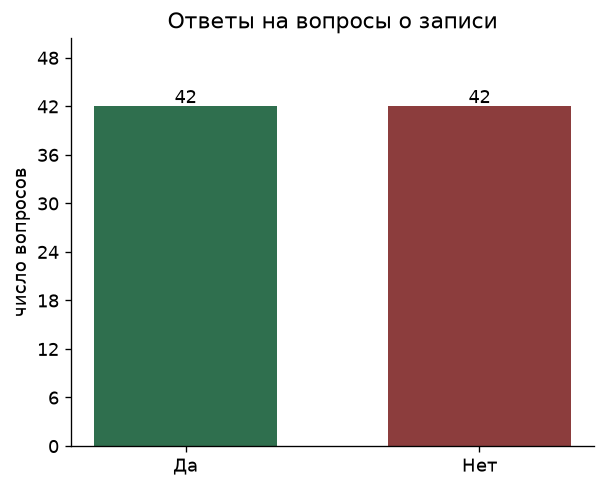

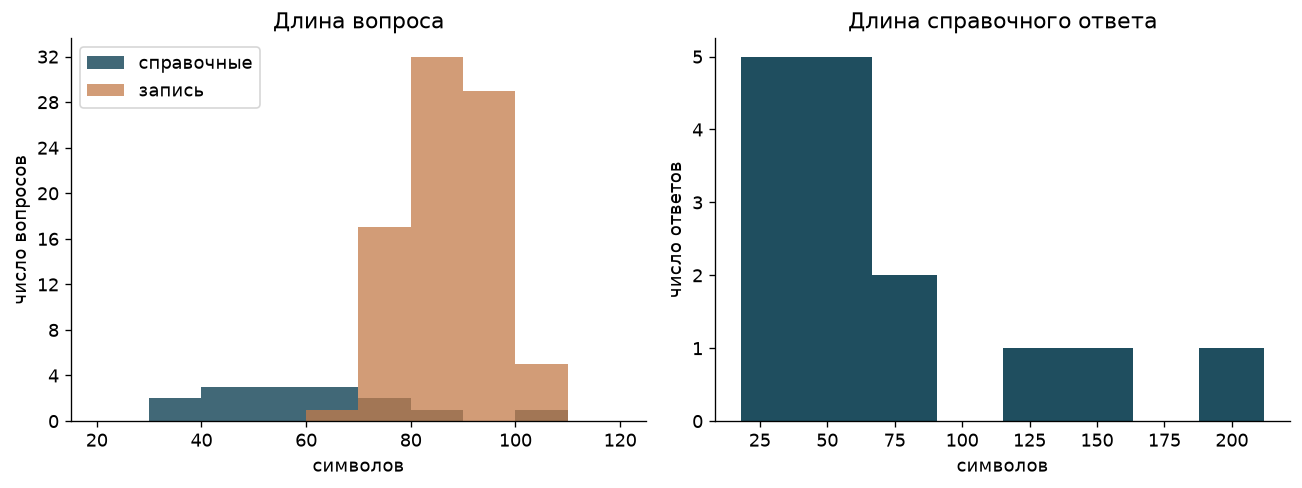

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))

answer_counts = Counter(row["answer"] for row in availability)
answer_labels = ["Да", "Нет"]
answer_values = [answer_counts[label] for label in answer_labels]
bars = ax.bar(answer_labels, answer_values, color=["#2f6f4e", "#8c3d3d"], width=0.62)
ax.set_title("Ответы на вопросы о записи")
ax.set_ylabel("число вопросов")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, answer_values, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, str(value), ha="center")
ax.set_ylim(0, max(answer_values) * 1.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(20, 130, 10)
axes[0].hist(
    lengths(knowledge, "question"),
    bins=bins,
    color=KIND_COLOR["knowledge"],
    alpha=0.85,
    label="справочные",
)
axes[0].hist(
    lengths(availability, "question"),
    bins=bins,
    color=KIND_COLOR["availability"],
    alpha=0.75,
    label="запись",
)
axes[0].set_title("Длина вопроса")
axes[0].set_xlabel("символов")
axes[0].set_ylabel("число вопросов")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

axes[1].hist(lengths(knowledge, "answer"), bins=8, color=KIND_COLOR["knowledge"])
axes[1].set_title("Длина справочного ответа")
axes[1].set_xlabel("символов")
axes[1].set_ylabel("число ответов")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()
plt.show()

## Что из этого следует

В датасете 15 справочных пар и 84 вопроса о записи. Это не потолок: справочных карточек можно было бы составить больше, но на сайте поликлиники их не было. Зато на mos.ru таких поликлик порядка 300 - под один и тот же шаблон можно автоматизировать 300 заведений. Сняты и спарсены пять карточек, и справочные вопросы построены только по ним. Запись синтетическая: 21 специальность с той же страницы, у каждой своя таблица и четыре вопроса. Клиент, который автоматизирует поддержку, может положить в ту же базу другие документы, и тогда доля справочных вопросов для RAG вырастет.

Вопросы о записи собраны ровно: у каждой из 21 специальностей четыре вопроса, «Да» и «Нет» по 42, и все 84 ответа совпадают со слотом в календаре.

В 16 вопросах короткое имя специальности входит в длинное. «Врач-терапевт» находится внутри «Врач-терапевт участковый». «Медсестра (медбрат)» находится внутри должностей «по массажу», «по физиотерапии» и «процедурной». По самому длинному имени каждый такой вопрос указывает на одну должность.

Справочные вопросы есть по всем пяти карточкам, по три на карточку. Повторов и противоречивых ответов нет.
